# 06 · Capstone: A Diffusion Transformer for the Interface, and the Modern Landscape

## Overview

The series so far, in one line each:

| Notebook | Idea | What it fixed | What it left open |
|---|---|---|---|
| 01 | Deep MLP + attributions | Explains *which* features separate the variants | Models $p(y\mid x)$ only |
| 02 | Autoencoder → VAE | A generative model you can sample | Over-smoothed samples |
| 03 | GAN → WGAN-GP → projection cGAN | Sharper, variance-preserving samples | Fragile training; quality vs coverage |
| 04 | Diffusion (v-prediction, DDIM, guidance) | Quality **and** coverage, stable training | Flat-vector MLP with a bottleneck; no residue structure |
| 05 | Attention over residue tokens + pair bias | Residue-level reasoning, data efficiency | Discriminative only |
| **06** | **Diffusion + attention** | Generation that respects residue structure | → today's research frontier |

Here we combine the last two ideas. We replace Notebook 04's MLP denoiser with a small **diffusion transformer**: residue tokens, contact-masked cross-attention with a pair bias (Notebook 05), and the diffusion step injected through **adaptive layer normalization** (DiT; Peebles & Xie, 2023). This is, in miniature, the design of AlphaFold 3's diffusion module and of RFdiffusion's denoiser. We then map every idea in the series onto real systems, including the papers in this repository's `research_papers/` folder.

## Learning objectives

1. Build a token-based denoiser and explain how adaptive LayerNorm conditions a transformer on time and class.
2. Explain why per-residue tokens remove the bottleneck that broke ε-prediction in Notebook 04.
3. Compare the MLP and transformer denoisers on the shared scorecard and a physical-plausibility check.
4. Place ESM, AlphaFold 2/3, RFdiffusion, ProteinMPNN, BindCraft and flow-matching models on the map built in this series.

**Runtime:** about 15 minutes on a laptop CPU; the transformer denoiser is much slower per epoch than the MLP.

In [1]:
import sys, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
sys.path.insert(0, ".")
from ppi_dl.data import load_ppi, set_seed
from ppi_dl.metrics import Scorecard, load_scorecards
from ppi_dl.plotting import plot_pca_overlay, plot_feature_distributions
from ppi_dl import diffusion as dfx          # Notebook 04's schedule, training loop and DDIM sampler

data = load_ppi("block")
iface = data.interface
Xtr, ytr = torch.tensor(data.X_train), torch.tensor(data.y_train)
D_IN = data.n_features
sc = Scorecard(data)
sc.reference()
print(data.summary())

split=block: train (3200, 4886), test (800, 4886), train class counts [1600, 1600], test class counts [400, 400]


## 1. From a flat vector to residue tokens, inside a denoiser

The denoiser receives a noisy frame $x_t$ (4,886 pair values) and must predict $v$ for every pair. We reuse Notebook 05's tokenization:

* scatter $x_t$ onto the $233 \times 156$ ACE2 × RBD grid (zeros where residues never touch);
* **ACE2 tokens** = rows, **RBD tokens** = columns, each projected to $d = 128$ and given a residue-identity embedding;
* **cross-attention** RBD → ACE2, masked to contacting pairs and biased by the (noisy) pair value;
* several **self-attention** blocks over RBD tokens;
* each RBD token predicts $v$ for its own column, and we read out the 4,886 measured pairs.

**Why this removes Notebook 04's bottleneck.** The MLP had to push all 4,886 numbers through 512 hidden units. Here the representation is $156 \times 128 \approx 20{,}000$ numbers wide, and each RBD token only has to output its own column. That column has at most 108 measured pairs, fewer than the token width.

### Conditioning with adaptive LayerNorm (adaLN)

How does a transformer know the noise level $t$ and the class $c$? DiT computes a conditioning vector $e = \text{emb}(t) + \text{emb}(c)$ and lets it **modulate every block**. LayerNorm's scale and shift are produced from $e$, and a learned gate scales each residual branch:
$$ h \leftarrow h + g(e) \odot \text{Attn}\big(\gamma(e) \odot \text{LN}(h) + \beta(e)\big). $$
The gates start at zero, so each block starts as the identity, which stabilizes training ("adaLN-Zero").

In [2]:
pair_a = torch.tensor(iface.pair_ace2_idx); pair_r = torch.tensor(iface.pair_rbd_idx)
flat_idx = pair_a * iface.n_rbd + pair_r                     # position of each pair in the 233x156 grid
contact = torch.zeros(iface.n_ace2, iface.n_rbd, dtype=torch.bool); contact[pair_a, pair_r] = True
mask_bias = torch.zeros(iface.n_rbd, iface.n_ace2); mask_bias[~contact.T] = float("-inf")

def to_grid(x):                                              # (B, 4886) -> (B, 233, 156)
    G = x.new_zeros(len(x), iface.n_ace2 * iface.n_rbd)
    G[:, flat_idx] = x
    return G.view(len(x), iface.n_ace2, iface.n_rbd)

def attention(q, k, v, bias=None):
    logits = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if bias is not None:
        logits = logits + bias
    return torch.softmax(logits, -1) @ v

class AdaLNBlock(nn.Module):
    """Transformer block (optionally cross-attention) with adaLN-Zero conditioning."""
    def __init__(self, d, heads, cond_dim):
        super().__init__()
        self.h, self.dk = heads, d // heads
        self.ln1, self.ln_kv, self.ln2 = (nn.LayerNorm(d, elementwise_affine=False) for _ in range(3))
        self.q, self.k, self.v, self.o = (nn.Linear(d, d) for _ in range(4))
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
        self.mod = nn.Linear(cond_dim, 6 * d)
        nn.init.zeros_(self.mod.weight); nn.init.zeros_(self.mod.bias)   # adaLN-Zero

    def heads_(self, x):
        B, n, _ = x.shape
        return x.view(B, n, self.h, self.dk).transpose(1, 2)

    def forward(self, x, e, kv=None, bias=None):
        s1, b1, g1, s2, b2, g2 = self.mod(e).unsqueeze(1).chunk(6, dim=-1)
        hq = self.ln1(x) * (1 + s1) + b1
        hkv = hq if kv is None else self.ln_kv(kv)
        a = attention(self.heads_(self.q(hq)), self.heads_(self.k(hkv)), self.heads_(self.v(hkv)), bias)
        a = self.o(a.transpose(1, 2).reshape(x.shape))
        x = x + g1 * a
        return x + g2 * self.ff(self.ln2(x) * (1 + s2) + b2)

class InterfaceDiT(nn.Module):
    def __init__(self, d=128, heads=4, n_self=3, cond_dim=128):
        super().__init__()
        self.heads = heads
        self.ace_in, self.rbd_in = nn.Linear(iface.n_rbd, d), nn.Linear(iface.n_ace2, d)
        self.ace_id = nn.Parameter(0.02 * torch.randn(iface.n_ace2, d))
        self.rbd_id = nn.Parameter(0.02 * torch.randn(iface.n_rbd, d))
        self.t_mlp = nn.Sequential(nn.Linear(128, cond_dim), nn.SiLU(), nn.Linear(cond_dim, cond_dim))
        self.c_emb = nn.Embedding(3, cond_dim)
        self.pair_bias = nn.Sequential(nn.Linear(1, 16), nn.GELU(), nn.Linear(16, heads))
        self.cross = AdaLNBlock(d, heads, cond_dim)
        self.selfs = nn.ModuleList([AdaLNBlock(d, heads, cond_dim) for _ in range(n_self)])
        self.out = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, iface.n_ace2))
        nn.init.zeros_(self.out[1].weight); nn.init.zeros_(self.out[1].bias)

    def forward(self, x, t, c):
        M = to_grid(x)                                           # (B, 233, 156)
        e = self.t_mlp(dfx.timestep_embedding(t)) + self.c_emb(c)
        a = self.ace_in(M) + self.ace_id
        r = self.rbd_in(M.transpose(1, 2)) + self.rbd_id
        pb = self.pair_bias(M.transpose(1, 2).unsqueeze(-1)).permute(0, 3, 1, 2)
        r = self.cross(r, e, kv=a, bias=pb + mask_bias)
        for blk in self.selfs:
            r = blk(r, e)
        cols = self.out(r)                                       # (B, 156, 233): v for each RBD column
        return cols.transpose(1, 2).reshape(len(x), -1)[:, flat_idx]

dit = InterfaceDiT()
mlp_ref = dfx.MLPDenoiser(D_IN)
n_dit, n_mlp = (sum(p.numel() for p in m.parameters()) for m in (dit, mlp_ref))
print(f"InterfaceDiT parameters: {n_dit:,}   MLP denoiser (Notebook 04): {n_mlp:,}  ({n_mlp / n_dit:.0f}x more)")
with torch.no_grad():
    out = dit(Xtr[:4], torch.tensor([0, 10, 500, 999]), torch.tensor([0, 1, 2, 0]))
print("output shape:", tuple(out.shape), "| starts at exactly zero (adaLN-Zero):", bool(out.abs().max() == 0))

InterfaceDiT parameters: 1,087,821   MLP denoiser (Notebook 04): 6,918,934  (6x more)
output shape: (4, 4886) | starts at exactly zero (adaLN-Zero): True


## 2. Training both denoisers on equal terms

Both models use the identical v-prediction objective, schedule, optimizer, EMA and number of epochs, from `ppi_dl/diffusion.py` (the Notebook 04 code). The only difference is the architecture.

epoch   0  loss 0.8421
epoch  10  loss 0.5759
epoch  20  loss 0.5173
training time: MLP 30s, InterfaceDiT 668s


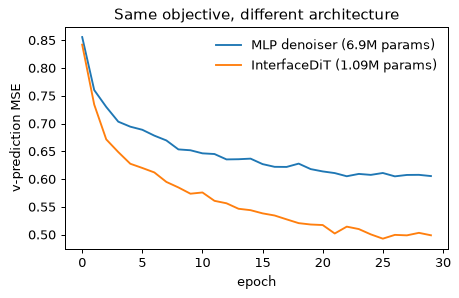

In [3]:
EPOCHS = 30
set_seed(0); t0 = time.time()
ema_mlp, loss_mlp = dfx.train_diffusion(dfx.MLPDenoiser(D_IN), Xtr, ytr, epochs=EPOCHS, verbose=False)
t_mlp = time.time() - t0
set_seed(0); t0 = time.time()
ema_dit, loss_dit = dfx.train_diffusion(InterfaceDiT(), Xtr, ytr, epochs=EPOCHS, log_every=10)
t_dit = time.time() - t0
print(f"training time: MLP {t_mlp:.0f}s, InterfaceDiT {t_dit:.0f}s")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(loss_mlp, label=f"MLP denoiser ({n_mlp / 1e6:.1f}M params)")
ax.plot(loss_dit, label=f"InterfaceDiT ({n_dit / 1e6:.2f}M params)")
ax.set_xlabel("epoch"); ax.set_ylabel("v-prediction MSE"); ax.legend(frameon=False)
ax.set_title("Same objective, different architecture"); plt.show()

## 3. Sampling and scoring

In [4]:
n_gen = len(data.X_test)
y_req = torch.tensor(data.y_test)
null = torch.full((n_gen,), dfx.NULL)
samples, timing = {}, {}
for name, m in [("MLP denoiser", ema_mlp), ("InterfaceDiT", ema_dit)]:
    set_seed(0); t0 = time.time()
    samples[name] = dfx.sample_ddim(m, null, D_IN)
    timing[name] = time.time() - t0
    sc.evaluate(samples[name], name=f"{name}, unconditional")
    set_seed(0)
    samples[name + " (w=1)"] = dfx.sample_ddim(m, y_req, D_IN, w=1.0)
    sc.evaluate(samples[name + " (w=1)"], data.y_test, name=f"{name}, guided w=1")
print({k: f"{v:.1f}s" for k, v in timing.items()}, "(DDIM-50, 800 samples)")
sc.table()

{'MLP denoiser': '1.9s', 'InterfaceDiT': '108.5s'} (DDIM-50, 800 samples)


,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
model,,,,,,,
real (train frames),0.993,0.009,0.640,0.799,0.854,1.000,NaN
"MLP denoiser, unconditional",1.142,0.039,0.716,0.436,0.978,NaN,1.011
"MLP denoiser, guided w=1",1.168,0.031,0.865,0.441,0.984,0.999,0.924
"InterfaceDiT, unconditional",0.963,0.080,0.414,0.106,0.997,NaN,1.223
"InterfaceDiT, guided w=1",1.156,0.079,0.714,0.134,0.999,1.000,1.154


### A physical-plausibility check

The scorecard measures statistical similarity. A structural biologist would also ask: **are the generated numbers possible at all?** Undo the standardization and the $1/d$ transform to get distances back in nm, then count the pair distances that fall outside the range ever observed in the MD data. This catches the failure mode a distribution metric can miss: a generated $1/d$ that is negative or near zero implies a negative or absurdly large distance, which no conformation can realize.

A stronger physical test (steric clashes, bond geometry) would need to know exactly which atoms these distances were measured between. The NIGMS module does not specify, and the values reach 0.24 nm, which is far too short for C$\alpha$–C$\alpha$ contacts, so they are evidently closest-atom distances. We therefore keep to the check we can justify.

In [5]:
real_d = data.to_distance(np.concatenate([data.X_train, data.X_test]))
lo, hi = real_d.min(0), real_d.max(0)

def plausibility(Xs):
    d = data.to_distance(Xs)
    bad = ~np.isfinite(d) | (d <= 0) | (d < lo) | (d > hi)
    return {"pairs outside MD range (%)": 100 * bad.mean(),
            "frames with at least one impossible pair (%)": 100 * bad.any(1).mean()}

rows = {"real held-out": plausibility(data.X_test)}
for name, Xs in samples.items():
    rows[name] = plausibility(Xs)
print(f"each frame contains {D_IN:,} pair values, so even a small per-pair error rate "
      f"affects most frames")
pd.DataFrame(rows).T.round(2)

each frame contains 4,886 pair values, so even a small per-pair error rate affects most frames


,pairs outside MD range (%),frames with at least one impossible pair (%)
real held-out,0.00,0.0
MLP denoiser,1.93,100.0
MLP denoiser (w=1),2.09,100.0
InterfaceDiT,0.87,100.0
InterfaceDiT (w=1),2.39,100.0


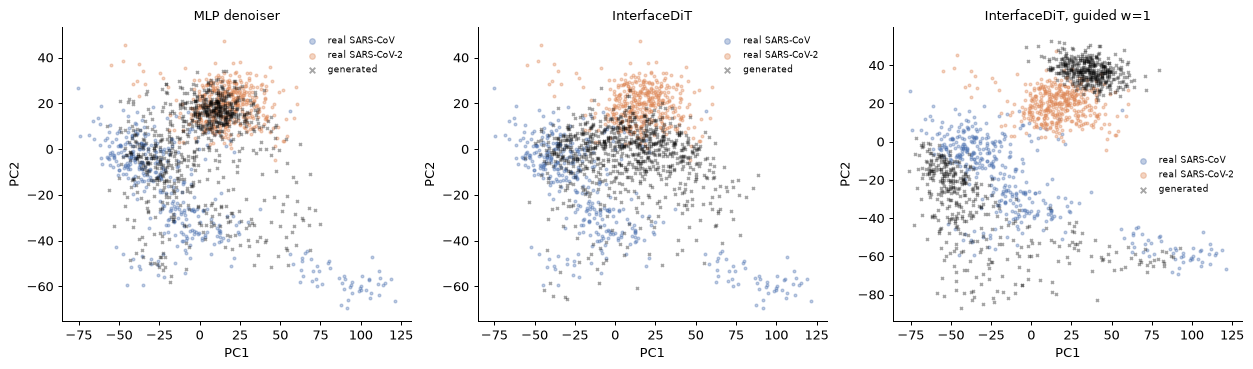

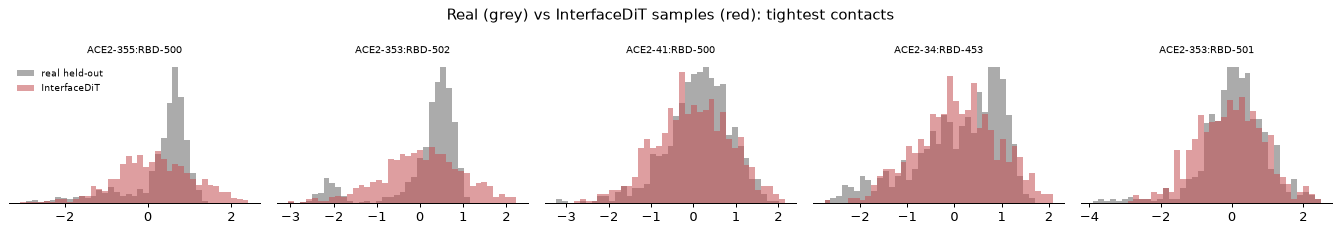

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
plot_pca_overlay(sc, samples["MLP denoiser"], title="MLP denoiser", ax=axes[0])
plot_pca_overlay(sc, samples["InterfaceDiT"], title="InterfaceDiT", ax=axes[1])
plot_pca_overlay(sc, samples["InterfaceDiT (w=1)"], title="InterfaceDiT, guided w=1", ax=axes[2])
fig.tight_layout(); plt.show()

show = np.argsort(data.mean)[::-1][:5]
plot_feature_distributions(data.X_test, samples["InterfaceDiT"], show, labels=iface.pair_labels("cov2"),
                           title="Real (grey) vs InterfaceDiT samples (red): tightest contacts",
                           names=("real held-out", "InterfaceDiT")); plt.show()

## 4. The whole series on one scorecard

In [7]:
prev = load_scorecards()
pick = [("02_VAE", "PCA-50 Gaussian (linear)"), ("02_VAE", "VAE (k=16, beta=1)"), ("02_VAE", "CVAE (k=16)"),
        ("03_GAN", "vanilla GAN"), ("03_GAN", "WGAN-GP"), ("03_GAN", "cWGAN-GP (projection)"),
        ("04_diffusion", "DDIM-50 (unconditional)"), ("04_diffusion", "DDIM-50, guidance w=1.0")]
rows = [prev[(prev.notebook == nb) & (prev.model == m)].assign(model=f"[{nb[:2]}] {m}") for nb, m in pick]
series = pd.concat(rows).set_index("model").drop(columns="notebook")
mine = sc.table()
mine.index = [i if i.startswith("real") else "[06] " + i for i in mine.index]
series = pd.concat([mine.loc[["real (train frames)"]], series, mine.drop(index="real (train frames)")])
series.to_csv("results/series_scorecard.csv")

# which architecture wins each metric, and how do both compare with Notebook 04's longer run?
# for each metric, a function saying whether the first value is the better one
better = {"std_ratio": lambda a, b: abs(a - 1) < abs(b - 1),   # closest to 1 wins
          "mmd": lambda a, b: a < b,
          "precision": lambda a, b: a > b,
          "coverage": lambda a, b: a > b,
          "c2st_auc": lambda a, b: a < b}
verdict = []
for m, is_better in better.items():
    dit = series.loc["[06] InterfaceDiT, unconditional", m]
    mlp = series.loc["[06] MLP denoiser, unconditional", m]
    nb04 = series.loc["[04] DDIM-50 (unconditional)", m]
    winner_value = dit if is_better(dit, mlp) else mlp
    verdict.append({"metric": m,
                    "InterfaceDiT (30 ep)": round(dit, 3),
                    "MLP denoiser (30 ep)": round(mlp, 3),
                    "winner": "InterfaceDiT" if is_better(dit, mlp) else "MLP denoiser",
                    "[04] MLP denoiser, 80 ep": round(nb04, 3),
                    "winner beats the 80-epoch run": "yes" if is_better(winner_value, nb04) else "no"})
display(pd.DataFrame(verdict).set_index("metric"))
series.round(3)

,InterfaceDiT (30 ep),MLP denoiser (30 ep),winner,"[04] MLP denoiser, 80 ep",winner beats the 80-epoch run
metric,,,,,
std_ratio,0.963,1.142,InterfaceDiT,1.280,yes
mmd,0.080,0.039,MLP denoiser,0.011,no
precision,0.414,0.716,MLP denoiser,0.590,yes
coverage,0.106,0.436,MLP denoiser,0.515,no
c2st_auc,0.997,0.978,MLP denoiser,0.871,no


,std_ratio,mmd,precision,coverage,c2st_auc,judge_acc,nn_ratio
real (train frames),0.993,0.009,0.640,0.799,0.854,1.000,NaN
[02] PCA-50 Gaussian (linear),1.000,0.015,0.082,0.062,0.956,NaN,1.681
"[02] VAE (k=16, beta=1)",0.517,0.077,0.499,0.278,0.982,NaN,1.193
[02] CVAE (k=16),0.571,0.060,0.660,0.336,0.967,1.000,1.079
[03] vanilla GAN,0.564,0.170,0.840,0.241,0.980,NaN,0.884
[03] WGAN-GP,0.784,0.023,0.266,0.136,1.000,NaN,1.442
[03] cWGAN-GP (projection),0.768,0.020,0.346,0.205,0.995,0.999,1.339
[04] DDIM-50 (unconditional),1.280,0.011,0.590,0.515,0.871,NaN,0.987
"[04] DDIM-50, guidance w=1.0",1.305,0.013,0.682,0.532,0.891,0.998,0.942
"[06] MLP denoiser, unconditional",1.142,0.039,0.716,0.436,0.978,NaN,1.011


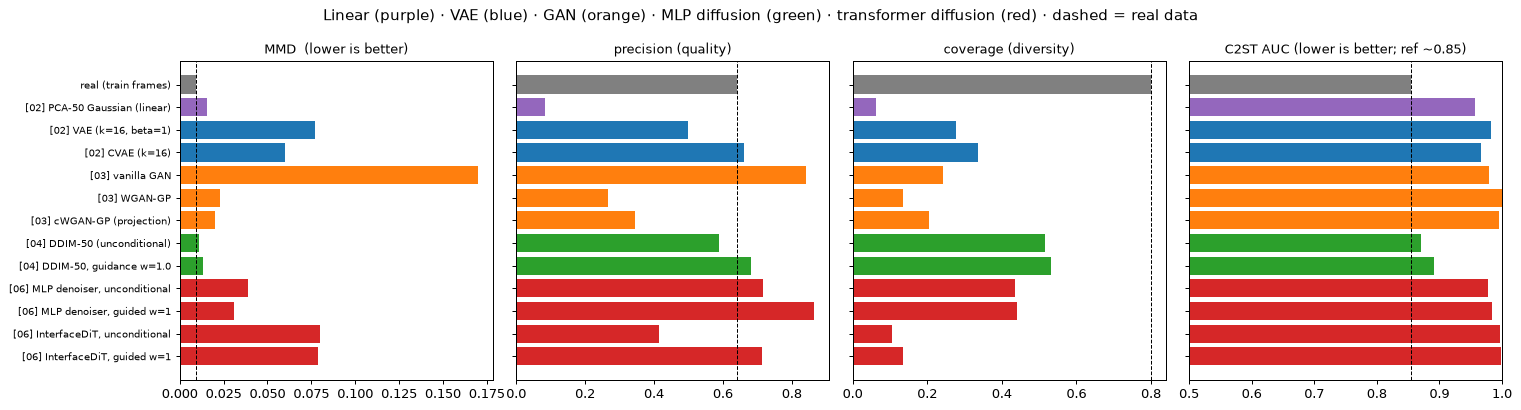

In [8]:
fam_color = lambda m: ("0.5" if m.startswith("real") else "tab:purple" if "PCA" in m else "tab:blue" if "VAE" in m
                       else "tab:orange" if "GAN" in m else "tab:green" if "[04]" in m else "tab:red")
metrics = [("mmd", "MMD  (lower is better)"), ("precision", "precision (quality)"),
           ("coverage", "coverage (diversity)"), ("c2st_auc", "C2ST AUC (lower is better; ref ~0.85)")]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, (m, title) in zip(axes, metrics):
    v = series[m]
    ax.barh(range(len(v)), v.values, color=[fam_color(i) for i in v.index])
    ax.axvline(series.loc["real (train frames)", m], color="k", ls="--", lw=0.8)
    ax.set_yticks(range(len(v))); ax.set_yticklabels(v.index if ax is axes[0] else [], fontsize=8)
    ax.set_title(title, fontsize=10); ax.invert_yaxis()
    if m == "c2st_auc":
        ax.set_xlim(0.5, 1.0)
fig.suptitle("Linear (purple) · VAE (blue) · GAN (orange) · MLP diffusion (green) · transformer diffusion (red) · dashed = real data")
fig.tight_layout(); plt.show()

**Reading the comparison honestly.** The cell below prints which architecture wins each
metric, rather than asserting an answer in advance.

Three things are worth noticing whatever the exact numbers.

**A better denoiser is not automatically a better generator.** The transformer reaches a
clearly lower v-prediction loss with 6× fewer parameters (first figure) — it is the better
model *of the training objective*. Whether that converts into a better match to the data
distribution is a separate question, and the scorecard answers it independently.

**Training budget is a confound.** Both models here were trained for 30 epochs to keep the
notebook runnable on a CPU, while Notebook 04's diffusion model had 80. The cell below
compares against that longer run. If the capstone models score worse, the honest conclusion is
about the budget, not the architecture — the transformer's loss curve in particular has not
flattened.

**Per-pair errors accumulate over a frame.** The plausibility table reports two very different
numbers. A per-pair error rate of around 1% sounds small, but each frame has 4,886 pairs, so
almost every generated frame contains at least one impossible distance. Real design pipelines
therefore enforce physical constraints during sampling rather than hoping a generator learns
them.

`nn_ratio` stays near 1 throughout: neither model is copying training frames.

## 5. The modern landscape, mapped onto this series

| System | Architecture (in this series' terms) | Generates / predicts | Ideas from |
|---|---|---|---|
| **ESM-2 / ESMFold** (Lin *et al.*, 2023) | Transformer trained by masked-token prediction on protein sequences | Sequence representations → structure | NB05 (attention, masked modelling) |
| **AlphaFold 2** (Jumper *et al.*, 2021) | Evoformer: attention over sequences and a **pair representation**, pair-biased attention, **triangle updates** | Structure from sequence (+MSA) | NB05 (pair bias) |
| **AlphaFold 3** (Abramson *et al.*, 2024) | **Pairformer** trunk + a **diffusion module** (transformer denoiser) over atom coordinates | Complexes of proteins, nucleic acids, ligands | NB04 + NB05 + NB06 |
| **RFdiffusion** (Watson *et al.*, 2023) | RoseTTAFold fine-tuned as a structure **denoiser**; conditioning on binding targets/motifs | New backbones, binders | NB04 (diffusion), NB06 (conditional denoiser) |
| **ProteinMPNN** (Dauparas *et al.*, 2022) | Message passing on a k-nearest-neighbour residue **graph** | Sequence for a given backbone | NB05 (graph-masked attention) |
| **BindCraft** (Pacesa *et al.*, 2025) | Back-propagates through AlphaFold 2 to optimize a binder ("hallucination") | One-shot binders | NB01 (gradients w.r.t. inputs) |
| **Flow matching** (Lipman *et al.*, 2023), e.g. FrameFlow, FoldFlow | Learns a velocity field along straight noise→data paths; few-step sampling | Backbones, ligands | NB04 (a close cousin of v-prediction) |

### Papers in this repository's `research_papers/` folder

* **Ouyang-Zhang *et al.*, "Triangle multiplication is all you need for biomolecular structure representations"** targets the cost of the AlphaFold 3-style Pairformer, the pair-representation machinery whose simplest form (a pair bias) you built in Notebook 05.
* **Qin *et al.*, "The dance of atoms: de novo protein design with diffusion model"** surveys diffusion-based protein design (Notebooks 04 and 06).
* **Xie *et al.*, "Distilled protein backbone generation"** attacks the many-steps cost of diffusion and flow models that you measured with DDPM vs DDIM.
* **Goel *et al.*, "Token-level guided discrete diffusion for membrane protein design"** applies diffusion to *discrete* sequence tokens with per-token guidance, combining Notebook 04's guidance idea with Notebook 05's tokens.
* **Cremer *et al.*, "FLOWR.ROOT"** is a flow-matching foundation model for structure-aware 3-D ligand generation and affinity prediction.
* **Liu *et al.*, "Monte Carlo tree diffusion with multiple experts for protein design"** combines diffusion with tree search over design decisions.
* **Ni & Buehler, "Agentic end-to-end de novo protein design for tailored dynamics using a language diffusion model"** conditions a diffusion language model on protein **dynamics**, the property MD captures and our models were trained on.
* **Beshkov & Malthe-Sørenssen, "Towards understanding the shape of representations in protein language models"** studies the geometry of transformer representations, a natural extension of Notebook 05's interpretation section.
* **Pacesa *et al.*, "One-shot design of functional protein binders with BindCraft"** and **Jendrusch *et al.*, "AlphaDesign"** use AlphaFold as a differentiable or hallucination-based design oracle.

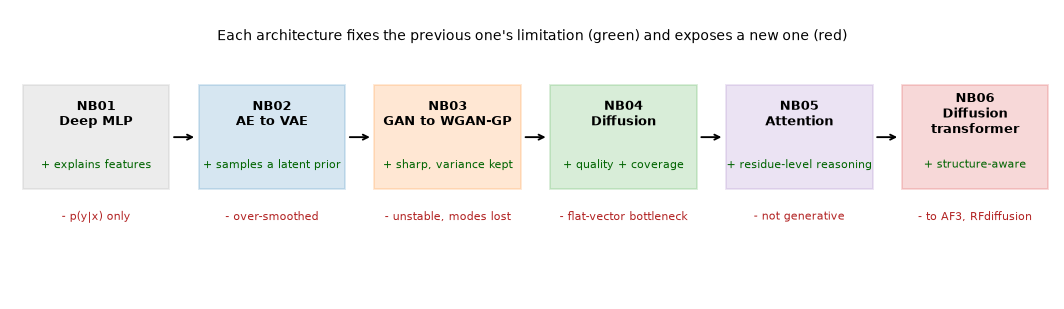

In [9]:
fig, ax = plt.subplots(figsize=(15, 4.2))
ax.set_xlim(0, 15); ax.set_ylim(0, 4.2); ax.axis("off")
stages = [
    ("NB01\nDeep MLP", "explains features", "p(y|x) only", "0.6"),
    ("NB02\nAE to VAE", "samples a latent prior", "over-smoothed", "tab:blue"),
    ("NB03\nGAN to WGAN-GP", "sharp, variance kept", "unstable, modes lost", "tab:orange"),
    ("NB04\nDiffusion", "quality + coverage", "flat-vector bottleneck", "tab:green"),
    ("NB05\nAttention", "residue-level reasoning", "not generative", "tab:purple"),
    ("NB06\nDiffusion\ntransformer", "structure-aware", "to AF3, RFdiffusion", "tab:red"),
]
w, gap = 2.1, 0.42
for i, (title, fixed, left, col) in enumerate(stages):
    x = 0.2 + i * (w + gap)
    ax.add_patch(plt.Rectangle((x, 1.6), w, 1.5, facecolor=col, alpha=0.18, edgecolor=col, lw=1.5))
    ax.text(x + w / 2, 2.68, title, ha="center", va="center", fontsize=10, weight="bold")
    ax.text(x + w / 2, 1.95, "+ " + fixed, ha="center", va="center", fontsize=8.5, color="darkgreen")
    ax.text(x + w / 2, 1.2, "- " + left, ha="center", va="center", fontsize=8.5, color="firebrick")
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + w + gap - 0.03, 2.35), xytext=(x + w + 0.03, 2.35),
                    arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(7.5, 3.75, "Each architecture fixes the previous one's limitation (green) and exposes a new one (red)",
        ha="center", fontsize=11)
plt.show()

## Challenge Problem 1: Flow matching in 20 lines

**Flow matching** (Lipman *et al.*, 2023; "rectified flow", Liu *et al.*, 2023) replaces the noising schedule with a straight line between data and noise, $x_s = (1-s)\,x_0 + s\,\epsilon$ for $s \in [0,1]$, and trains a network to predict the **velocity** $u = \epsilon - x_0$. Sampling integrates $dx/ds = u_\theta(x, s)$ from $s=1$ (noise) to $s=0$ (data) with a few Euler steps.

Using `dfx.MLPDenoiser(D_IN)` as the velocity network (pass `t = (s * 999).long()` as its time input and `c = NULL`):

1. train for 40 epochs with the loss $\lVert u_\theta(x_s, s) - (\epsilon - x_0)\rVert^2$;
2. sample 800 frames with 20 Euler steps;
3. score them with `sc.evaluate(..., store=False)` and compare with the MLP diffusion model.

In [10]:
# Start your code here

### Challenge Problem 1 Solution

In [11]:
set_seed(0)
fm = dfx.MLPDenoiser(D_IN)
opt = torch.optim.Adam(fm.parameters(), 1e-3)
null_b = lambda n: torch.full((n,), dfx.NULL)
for ep in range(40):
    perm = torch.randperm(len(Xtr))
    for i in range(0, len(Xtr), 64):
        x0 = Xtr[perm[i:i + 64]]; n = len(x0)
        s = torch.rand(n); eps = torch.randn_like(x0)
        xs = (1 - s[:, None]) * x0 + s[:, None] * eps
        loss = F.mse_loss(fm(xs, (s * 999).long(), null_b(n)), eps - x0)
        opt.zero_grad(); loss.backward(); opt.step()
fm.eval()

@torch.no_grad()
def sample_flow(model, n, steps=20):
    x = torch.randn(n, D_IN); ds = 1.0 / steps
    for k in range(steps):
        s = 1.0 - k * ds
        x = x - ds * model(x, torch.full((n,), int(s * 999)), null_b(n))
    return x.numpy()

set_seed(0)
r_fm = sc.evaluate(sample_flow(fm, n_gen), name="flow matching, 20 Euler steps (40 ep)", store=False)
r_dd = [r for r in sc.rows if r["model"] == "MLP denoiser, unconditional"][0]
pd.DataFrame([r_fm, r_dd]).set_index("model")[["mmd", "precision", "coverage", "std_ratio", "c2st_auc"]].round(3)

,mmd,precision,coverage,std_ratio,c2st_auc
model,,,,,
"flow matching, 20 Euler steps (40 ep)",0.044,0.594,0.381,1.211,0.933
"MLP denoiser, unconditional",0.039,0.716,0.436,1.142,0.978


## Challenge Problem 2: Where would you take this next?

Pick one direction and sketch (in a few sentences, or in code) how you would implement it with the pieces from this series:

1. **Generate structures, not distances.** Replace the 4,886 distances with C$\alpha$ coordinates and use an SE(3)-equivariant denoiser, as RFdiffusion and AlphaFold 3 do. Why does a distance representation avoid the need for equivariance, and what does it lose?
2. **Design, not just describe.** Use classifier-free guidance toward "SARS-CoV-2-like" interfaces as a proxy for tighter binding, then hand the generated contact maps to a sequence-design model (ProteinMPNN) or a structure predictor for validation.
3. **Physics-aware generation.** Add the clash check from Section 3 as a guidance term during sampling (gradient of a clash penalty with respect to $x_t$). This is **classifier guidance** with a physics "classifier".

## Final summary

* The series followed the real history of deep generative modelling: **likelihood with a latent** (VAE) → **adversarial** (GAN) → **denoising** (diffusion). Each step fixed a measurable weakness of the last, and our scorecard made those weaknesses visible on real MD data.
* In parallel, **attention** moved from a translation trick to the backbone of protein modelling, because it lets residues reason about their partners with shared weights.
* Combining the two, a transformer that denoises residue tokens, is the core design of today's leading structure-generation systems.

## References

* Peebles W., Xie S. (2023) Scalable diffusion models with transformers. *ICCV*.
* Lin Z. *et al.* (2023) Evolutionary-scale prediction of atomic-level protein structure with a language model. *Science* 379, 1123–1130.
* Jumper J. *et al.* (2021) Highly accurate protein structure prediction with AlphaFold. *Nature* 596, 583–589.
* Abramson J. *et al.* (2024) Accurate structure prediction of biomolecular interactions with AlphaFold 3. *Nature* 630, 493–500.
* Watson J. L. *et al.* (2023) De novo design of protein structure and function with RFdiffusion. *Nature* 620, 1089–1100.
* Dauparas J. *et al.* (2022) Robust deep learning–based protein sequence design using ProteinMPNN. *Science* 378, 49–56.
* Pacesa M. *et al.* (2025) One-shot design of functional protein binders with BindCraft. *Nature* 646, 483–492.
* Lipman Y. *et al.* (2023) Flow matching for generative modeling. *ICLR*.
* Liu X., Gong C., Liu Q. (2023) Flow straight and fast: learning to generate and transfer data with rectified flow. *ICLR*.
* Papers in `research_papers/` as listed in Section 5.